# Part 7 — Full Müller–Brown benchmark (Table 10 / Figure 8)
See [README.md](README.md) for metrics and the paper's numbers.

`N_SEEDS = 1` reuses the models from Parts 3–6 (fast). The paper uses 10 models per method; increase `N_SEEDS`
(each extra seed trains 4 models, ~15 min) and `ex.STEPS_SCALE` for a more faithful reproduction.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent            # notebooks live one level below the project root
sys.path.insert(0, str(ROOT))
import numpy as np, torch, matplotlib.pyplot as plt
torch.set_default_dtype(torch.float64)      # float64: the FP estimator uses finite differences with sigma=1e-4
torch.set_num_threads(8)
from scoremd import sde, models, losses, sampling, simulate, metrics, potentials, plotting, experiments as ex
%matplotlib inline
import pandas as pd

In [2]:
N_SEEDS = 1
ex.STEPS_SCALE = 1.0
SIM_STEPS = 10_000
x, info = ex.load_system('mb'); rng = metrics.hist_range(x)
methods = {  # name -> (model config, diffusion time used for simulation)
    'Diffusion': ('mb_diffusion', ex.T_EVAL),
    'Two For One': ('mb_diffusion', ex.T_TWO_FOR_ONE),
    'Mixture': ('mb_mixture', ex.T_EVAL),
    'Fokker-Planck': ('mb_fp', ex.T_EVAL),
    'Both': ('mb_both', ex.T_EVAL),
}

## Reference noise floor (independent true-force simulation vs. data)

In [3]:
ref_rows = []
for seed in range(max(N_SEEDS, 2)):
    sim_true, _ = ex.simulate_model(None, x, force=ex.mb_true_force_normalised(info), n_steps=SIM_STEPS, seed=100 + seed)
    ref_rows.append(ex.compare(sim_true, x, seed=seed))
print('Reference (true force):', pd.DataFrame(ref_rows).agg(['mean', 'std']).round(4).to_dict())

Reference (true force): {'pmf': {'mean': 2.2821, 'std': 0.0258}, 'js': {'mean': 0.0105, 'std': 0.0001}}


## Run all methods

In [4]:
rows, last = [], {}
for seed in range(N_SEEDS):
    for name, (cfg, t_eval) in methods.items():
        m = ex.get_model(cfg, seed=seed, verbose=False)
        iid = ex.iid_samples(m, seed=seed)
        sim, _ = ex.simulate_model(m, x, t_eval=t_eval, n_steps=SIM_STEPS, seed=seed)
        ci, cs = ex.compare(iid, x, seed=seed), ex.compare(sim, x, seed=seed)
        rows.append(dict(method=name, seed=seed, iid_js=ci['js'], sim_js=cs['js'], iid_pmf=ci['pmf'], sim_pmf=cs['pmf'],
                         sim_small_basin=ex.mb_small_basin_fraction(sim, info)))
        last[name] = (iid, sim)
        print(rows[-1])
df = pd.DataFrame(rows)
df.to_csv(ex.RESULTS / 'table10_reproduction.csv', index=False)

{'method': 'Diffusion', 'seed': 0, 'iid_js': 0.037013273158401534, 'sim_js': 0.13395215265329102, 'iid_pmf': 3.514866734952879, 'sim_pmf': 5.878286722636023, 'sim_small_basin': 0.068}
{'method': 'Two For One', 'seed': 0, 'iid_js': 0.037013273158401534, 'sim_js': 0.11254676906411622, 'iid_pmf': 3.514866734952879, 'sim_pmf': 5.357692941926316, 'sim_small_basin': 0.004111111111111111}
{'method': 'Mixture', 'seed': 0, 'iid_js': 0.0552455975549865, 'sim_js': 0.0960947350446289, 'iid_pmf': 3.8601389946153217, 'sim_pmf': 2.6844860920825737, 'sim_small_basin': 0.03661111111111111}
{'method': 'Fokker-Planck', 'seed': 0, 'iid_js': 0.22482829817956704, 'sim_js': 0.21783564772265265, 'iid_pmf': 11.614645880992802, 'sim_pmf': 11.89720850949185, 'sim_small_basin': 0.15383333333333332}
{'method': 'Both', 'seed': 0, 'iid_js': 0.15368925557047794, 'sim_js': 0.13340139945606527, 'iid_pmf': 5.555349191864121, 'sim_pmf': 4.773897038442195, 'sim_small_basin': 0.06111111111111111}


## Table 10 (ours)

In [5]:
agg = df.drop(columns='seed').groupby('method', sort=False).agg(['mean', 'std'] if N_SEEDS > 1 else ['mean'])
print('reference small-basin fraction:', round(ex.mb_small_basin_fraction(x, info), 4))
agg.round(4)

reference small-basin fraction: 0.1369


,iid_js,sim_js,iid_pmf,sim_pmf,sim_small_basin
,mean,mean,mean,mean,mean
method,,,,,
Diffusion,0.0370,0.1340,3.5149,5.8783,0.0680
Two For One,0.0370,0.1125,3.5149,5.3577,0.0041
Mixture,0.0552,0.0961,3.8601,2.6845,0.0366
Fokker-Planck,0.2248,0.2178,11.6146,11.8972,0.1538
Both,0.1537,0.1334,5.5553,4.7739,0.0611


## Figure 8 (ours): iid row and sim row

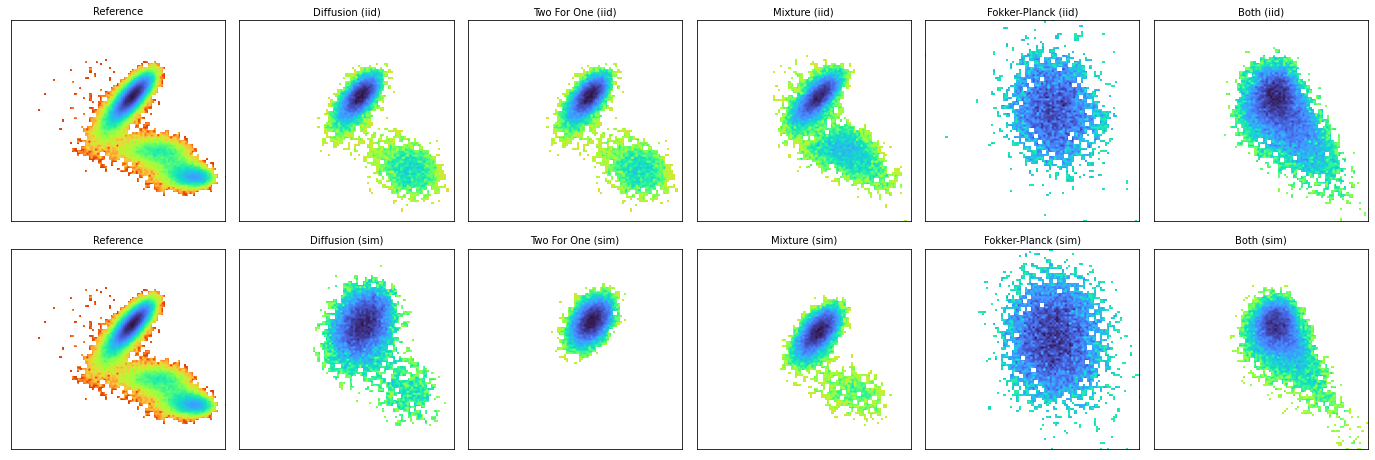

In [6]:
fig, ax = plt.subplots(2, len(methods) + 1, figsize=(3.2 * (len(methods) + 1), 6.5))
plotting.free_energy_hist(ax[0, 0], x, rng, title='Reference'); plotting.free_energy_hist(ax[1, 0], x, rng, title='Reference')
for col, (name, (iid, sim)) in enumerate(last.items(), start=1):
    plotting.free_energy_hist(ax[0, col], iid, rng, title=f'{name} (iid)')
    plotting.free_energy_hist(ax[1, col], sim, rng, title=f'{name} (sim)')
plt.tight_layout(); plt.savefig(ex.RESULTS / 'fig8_reproduction.png', dpi=120)

## How to read the result
* Paper claim to test: Diffusion's sim error ≫ its iid error; FP-regularised models close that gap; Both is best for sim.
* Compare each sim number to the **reference noise floor**, not to 0.
* Record your numbers next to the paper's in [../RESULTS.md](../RESULTS.md).